## Industrial Energy Consumption Prediction

### Problem statement
Predict industrial electricity consumption (`Usage_kWh`) from electrical measurements, power-factor variables, carbon dioxide emissions, time-derived features, and operational categories.


In [1]:

# Imports and reproducibility
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")


## 1. Load the dataset

In [2]:

# Update only this path if your local dataset is stored elsewhere.
from pathlib import Path

# Works when the notebook is opened from the repository root or from notebooks/.
candidate_paths = [
    Path("../data/Steel_industry_data.csv"),
    Path("data/Steel_industry_data.csv"),
    Path("Steel_industry_data.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Steel_industry_data.csv not found. Place it in data/ or beside the notebook.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Shape: (35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.1700,2.9500,0.0000,0.0000,73.2100,100.0000,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.0000,4.4600,0.0000,0.0000,66.7700,100.0000,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.2400,3.2800,0.0000,0.0000,70.2800,100.0000,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.3100,3.5600,0.0000,0.0000,68.0900,100.0000,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.8200,4.5000,0.0000,0.0000,64.7200,100.0000,4500,Weekday,Monday,Light_Load



### Dataset audit
Report shape, data types, missing values, duplicates, and the target distribution.

**Team observation to write after running:** What stands out about the dataset size, target range/distribution, and data quality?


In [3]:

print("DATA TYPES")
display(df.dtypes.to_frame("dtype"))

print("\nMISSING VALUES")
display(df.isna().sum().to_frame("missing"))

print("\nDUPLICATES:", df.duplicated().sum())

print("\nTARGET SUMMARY")
display(df["Usage_kWh"].describe().to_frame().T)

print("\nCATEGORICAL DISTRIBUTIONS")
for col in ["WeekStatus", "Day_of_week", "Load_Type"]:
    print(f"\n{col}")
    display(df[col].value_counts().to_frame("count"))


DATA TYPES


,dtype
date,object
Usage_kWh,float64
Lagging_Current_Reactive.Power_kVarh,float64
Leading_Current_Reactive_Power_kVarh,float64
CO2(tCO2),float64
Lagging_Current_Power_Factor,float64
Leading_Current_Power_Factor,float64
NSM,int64
WeekStatus,object
Day_of_week,object



MISSING VALUES


,missing
date,0
Usage_kWh,0
Lagging_Current_Reactive.Power_kVarh,0
Leading_Current_Reactive_Power_kVarh,0
CO2(tCO2),0
Lagging_Current_Power_Factor,0
Leading_Current_Power_Factor,0
NSM,0
WeekStatus,0
Day_of_week,0



DUPLICATES: 0

TARGET SUMMARY


...

,count
WeekStatus,
Weekday,25056
Weekend,9984



Day_of_week


,count
Day_of_week,
Monday,5088
Tuesday,4992
Wednesday,4992
Thursday,4992
Friday,4992
Saturday,4992
Sunday,4992



Load_Type


,count
Load_Type,
Light_Load,18072
Medium_Load,9696
Maximum_Load,7272


## 2. Parse date and perform feature engineering

In [4]:

df["date"] = pd.to_datetime(df["date"], dayfirst=True)

# Time-derived features motivated by the reference paper.
df["Hour"] = df["date"].dt.hour
df["Minute"] = df["date"].dt.minute
df["Month"] = df["date"].dt.month
df["Day_of_month"] = df["date"].dt.day
df["Day_of_week_num"] = df["date"].dt.dayofweek
df["Is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)

# Cyclical encoding captures the circular nature of time-of-day and month.
df["Hour_sin"] = np.sin(2 * np.pi * (df["Hour"] + df["Minute"]/60) / 24)
df["Hour_cos"] = np.cos(2 * np.pi * (df["Hour"] + df["Minute"]/60) / 24)
df["Month_sin"] = np.sin(2 * np.pi * (df["Month"] - 1) / 12)
df["Month_cos"] = np.cos(2 * np.pi * (df["Month"] - 1) / 12)

print("Date range:", df["date"].min(), "to", df["date"].max())
display(df.head())


Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,Hour,Minute,Month,Day_of_month,Day_of_week_num,Is_weekend,Hour_sin,Hour_cos,Month_sin,Month_cos
0,2018-01-01 00:15:00,3.1700,2.9500,0.0000,0.0000,73.2100,100.0000,900,Weekday,Monday,Light_Load,0,15,1,1,0,0,0.0654,0.9979,0.0000,1.0000
1,2018-01-01 00:30:00,4.0000,4.4600,0.0000,0.0000,66.7700,100.0000,1800,Weekday,Monday,Light_Load,0,30,1,1,0,0,0.1305,0.9914,0.0000,1.0000
2,2018-01-01 00:45:00,3.2400,3.2800,0.0000,0.0000,70.2800,100.0000,2700,Weekday,Monday,Light_Load,0,45,1,1,0,0,0.1951,0.9808,0.0000,1.0000
3,2018-01-01 01:00:00,3.3100,3.5600,0.0000,0.0000,68.0900,100.0000,3600,Weekday,Monday,Light_Load,1,0,1,1,0,0,0.2588,0.9659,0.0000,1.0000
4,2018-01-01 01:15:00,3.8200,4.5000,0.0000,0.0000,64.7200,100.0000,4500,Weekday,Monday,Light_Load,1,15,1,1,0,0,0.3214,0.9469,0.0000,1.0000



### Feature-engineering justification
The reference paper derives additional characteristics from date/time, including seconds from midnight, weekday/weekend status, and day-of-week. It reports strong time patterns in industrial energy consumption. Here, the original `NSM` and categorical time fields are retained, and additional hour/month representations are created to let the models capture periodic patterns.

**Team observation to write:** Explain why at least one engineered feature could improve prediction.


## 3. Exploratory Data Analysis

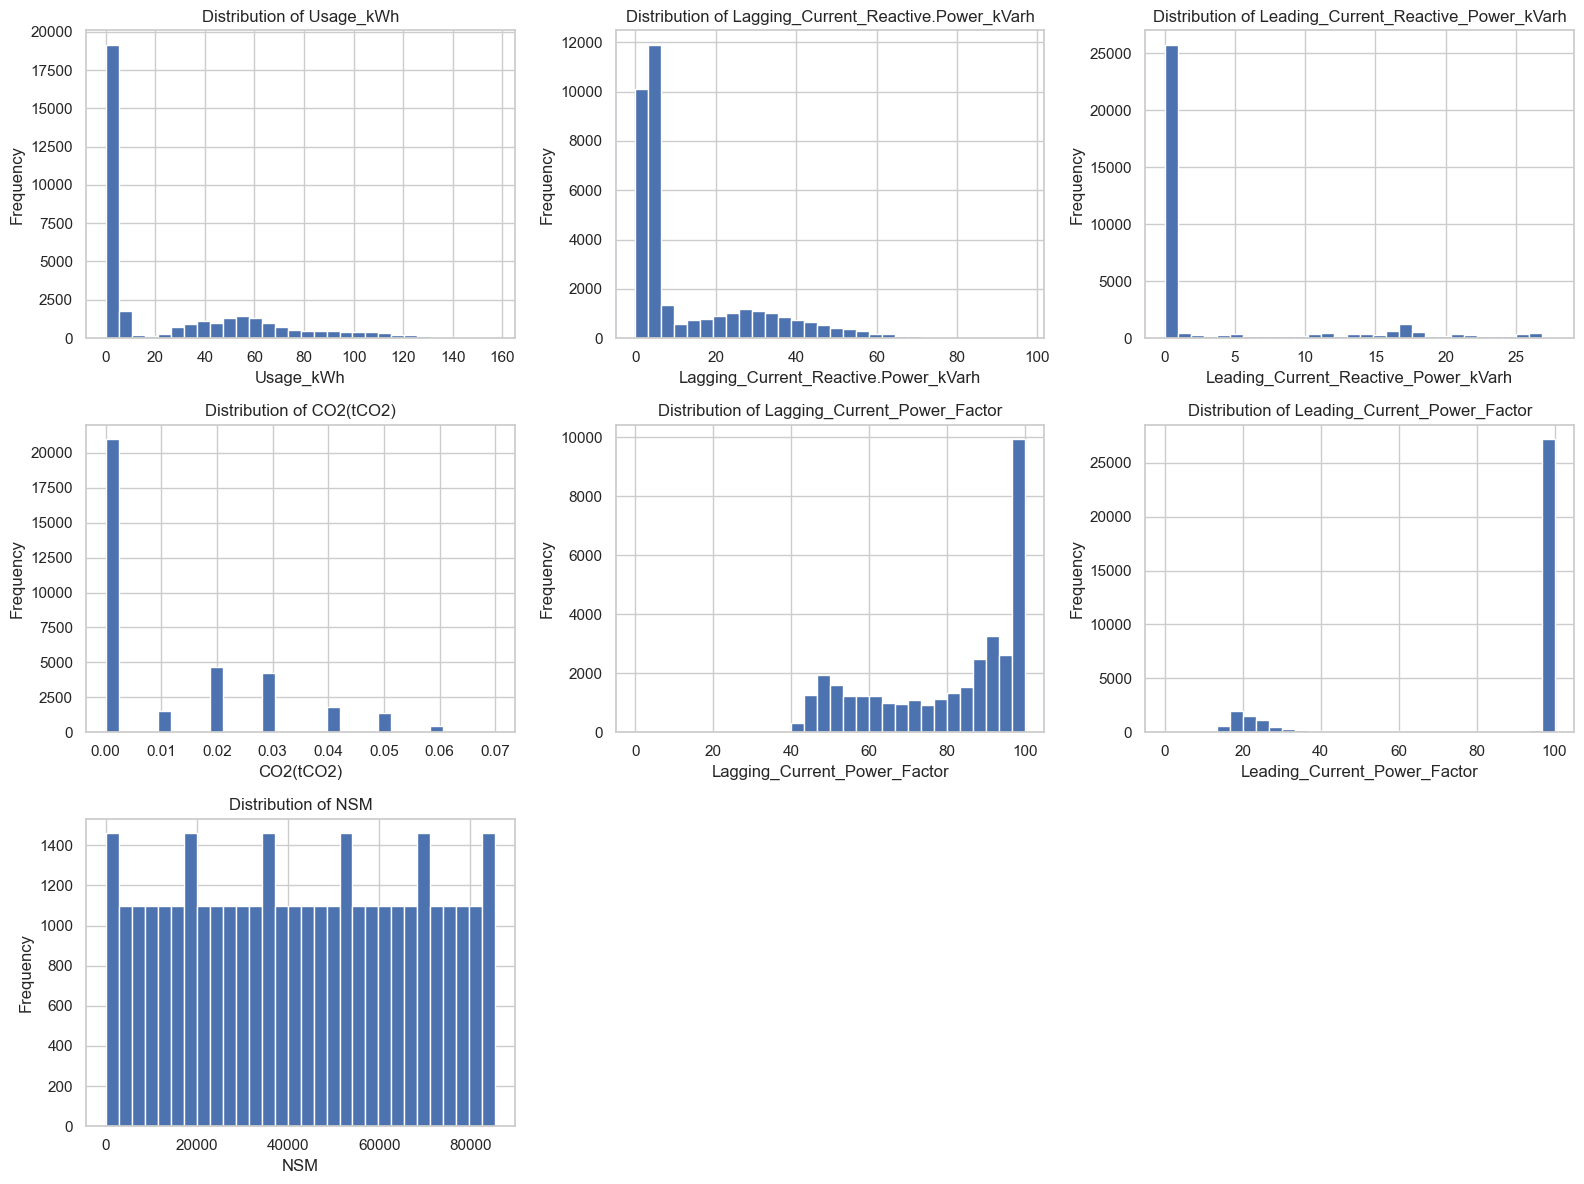

In [5]:

# Numerical feature distribution plots
numeric_eda = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM"
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for ax, col in zip(axes, numeric_eda):
    ax.hist(df[col].dropna(), bins=30)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

for ax in axes[len(numeric_eda):]:
    ax.axis("off")

plt.tight_layout()
plt.show()



**Observation:** Write one concise observation about the target distribution and one about the feature distributions. In particular, note skewness/outliers where relevant.


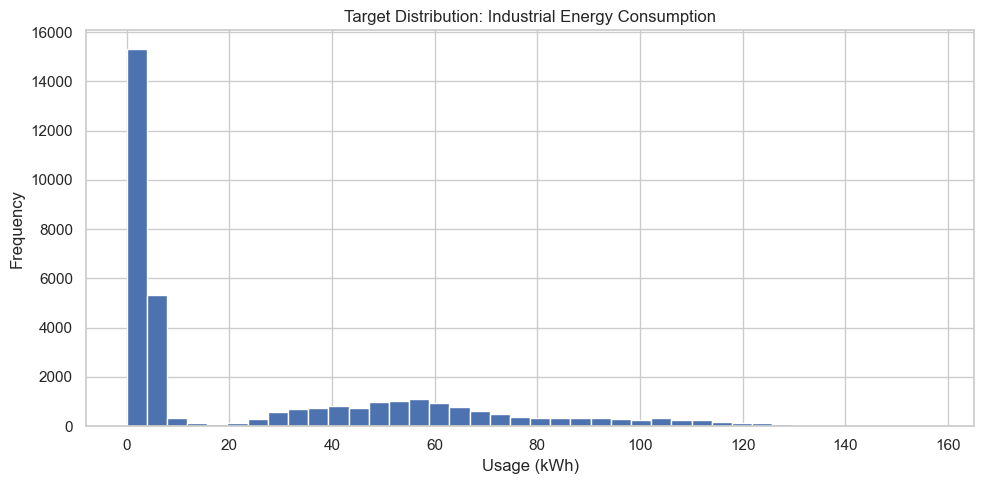

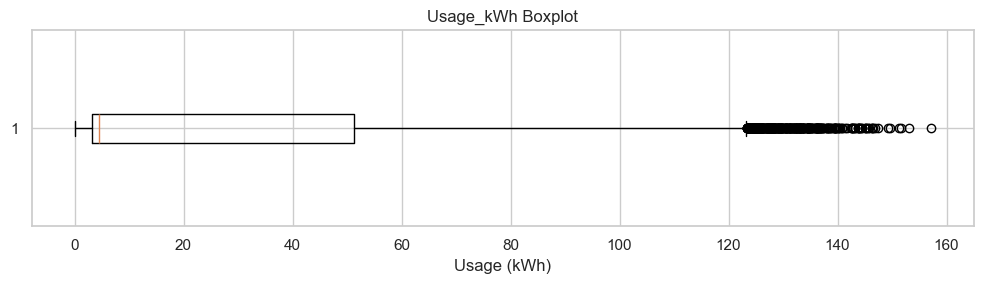

In [6]:

# Target distribution
plt.figure(figsize=(10, 5))
plt.hist(df["Usage_kWh"].dropna(), bins=40)
plt.title("Target Distribution: Industrial Energy Consumption")
plt.xlabel("Usage (kWh)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Boxplot for outlier inspection
plt.figure(figsize=(10, 3))
plt.boxplot(df["Usage_kWh"].dropna(), vert=False)
plt.title("Usage_kWh Boxplot")
plt.xlabel("Usage (kWh)")
plt.tight_layout()
plt.show()



**Observation:** The boxplot is an outlier check, not an automatic reason to delete records. Explain whether extreme values appear to be plausible industrial consumption observations or data errors, and what treatment is justified.


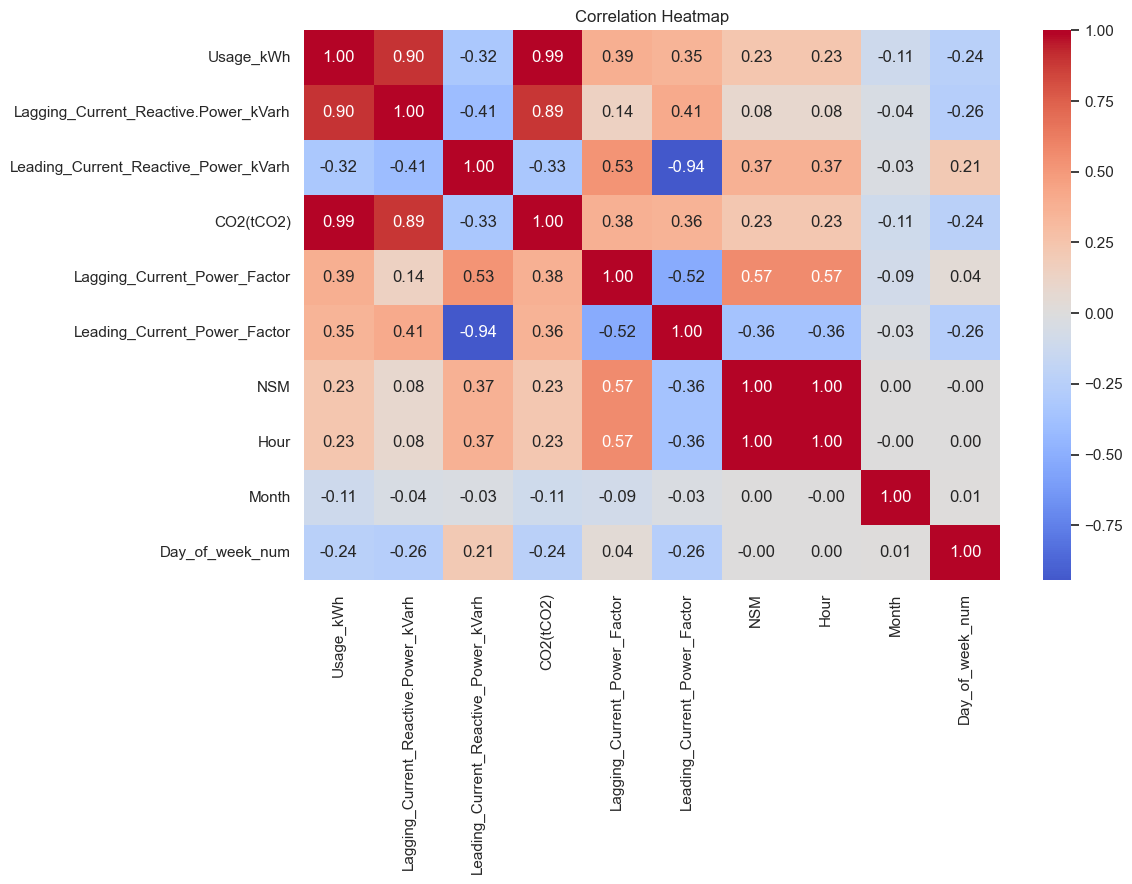

In [7]:

# Correlation heatmap for numerical variables
corr_cols = numeric_eda + [
    "Hour", "Month", "Day_of_week_num"
]
corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()



**Observation:** Identify the strongest positive/negative relationships with `Usage_kWh`. Do not equate correlation with causation.


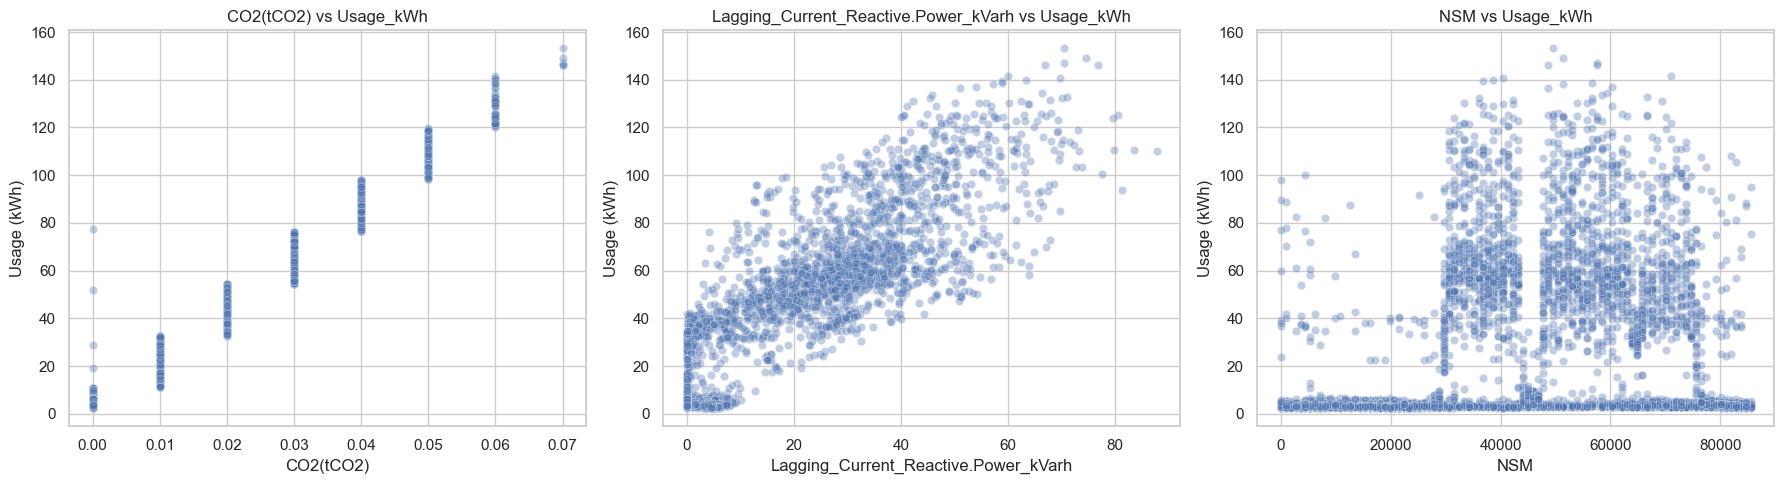

In [8]:

# At least two feature-target scatter plots
scatter_cols = [
    "CO2(tCO2)",
    "Lagging_Current_Reactive.Power_kVarh",
    "NSM"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, scatter_cols):
    sns.scatterplot(data=df.sample(min(5000, len(df)), random_state=RANDOM_STATE),
                    x=col, y="Usage_kWh", alpha=0.35, ax=ax)
    ax.set_title(f"{col} vs Usage_kWh")
    ax.set_xlabel(col)
    ax.set_ylabel("Usage (kWh)")

plt.tight_layout()
plt.show()



**Observation:** Write what each scatter plot suggests about the relationship shape, spread, or possible outliers.


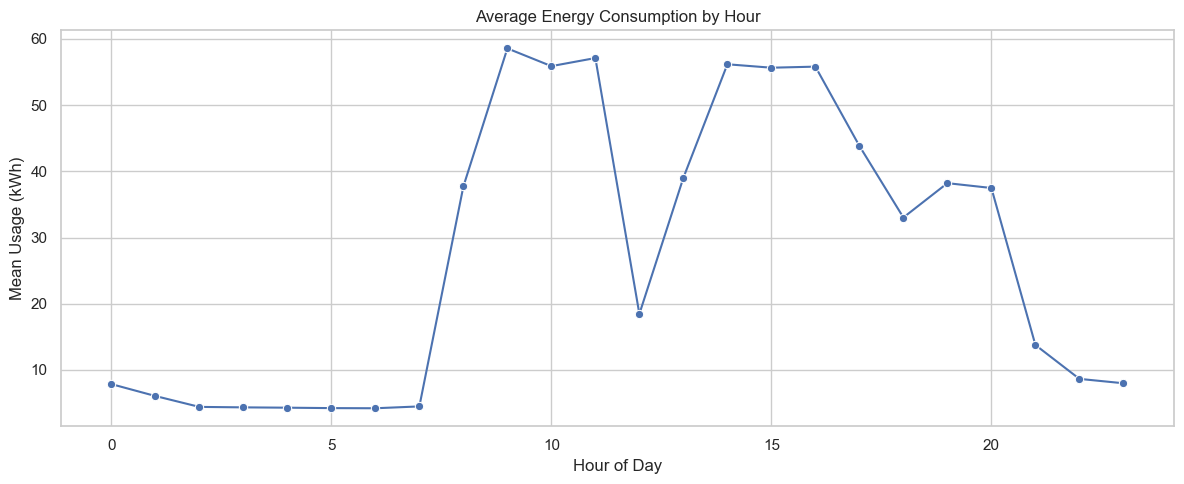

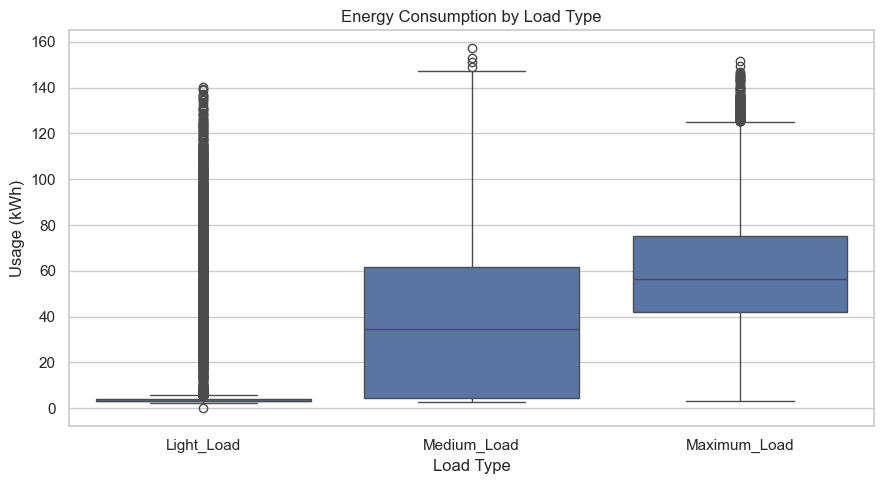

In [9]:

# Time-pattern visualization
hourly = df.groupby("Hour", as_index=False)["Usage_kWh"].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly, x="Hour", y="Usage_kWh", marker="o")
plt.title("Average Energy Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Usage (kWh)")
plt.tight_layout()
plt.show()

load_order = ["Light_Load", "Medium_Load", "Maximum_Load"]
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Load_Type", y="Usage_kWh", order=load_order)
plt.title("Energy Consumption by Load Type")
plt.xlabel("Load Type")
plt.ylabel("Usage (kWh)")
plt.tight_layout()
plt.show()



**Observation:** Explain any clear time-of-day or load-type pattern visible in the plots.


## 4. Data cleaning and train/test split

In [10]:

# Outlier check using IQR (reported only here; do not automatically delete valid extreme readings).
q1 = df["Usage_kWh"].quantile(0.25)
q3 = df["Usage_kWh"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_mask = (df["Usage_kWh"] < lower) | (df["Usage_kWh"] > upper)

print(f"IQR lower bound: {lower:.4f}")
print(f"IQR upper bound: {upper:.4f}")
print(f"Potential target outliers by IQR rule: {outlier_mask.sum():,} ({outlier_mask.mean()*100:.2f}%)")
print("No rows are deleted automatically; domain-valid peaks can contain useful signal.")

# Features / target
drop_cols = ["Usage_kWh", "date"]
X = df.drop(columns=drop_cols)
y = df["Usage_kWh"]

# Stratify using target bins so the regression split has a similar target distribution.
# This is a split-strategy convenience, not a classification target.
y_bins = pd.qcut(y, q=10, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_bins
)

print("Train:", X_train.shape, "Test:", X_test.shape)


IQR lower bound: -68.8562
IQR upper bound: 123.2937
Potential target outliers by IQR rule: 328 (0.94%)
No rows are deleted automatically; domain-valid peaks can contain useful signal.
Train: (28032, 19) Test: (7008, 19)



### Leakage check
The split happens before model fitting. Imputers, one-hot encoders, and scalers are placed inside pipelines so they are fitted only on the training data. This follows the capstone rule that preprocessing must not be fitted on the full dataset.


## 5. Preprocessing pipeline

In [11]:

categorical_features = ["WeekStatus", "Day_of_week", "Load_Type"]
numeric_features = [c for c in X.columns if c not in categorical_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)


Numeric features: 16
Categorical features: ['WeekStatus', 'Day_of_week', 'Load_Type']



## 6. Train the 10 required regression algorithms

The capstone requires these ten models on the same held-out test split:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. ElasticNet Regression
5. Polynomial Regression
6. Decision Tree Regressor
7. Random Forest Regressor
8. Gradient Boosting Regressor
9. Support Vector Regressor
10. K-Nearest Neighbors Regressor



### Polynomial degree comparison
The rubric asks to compare polynomial degrees. A full degree-3 expansion over every one-hot encoded feature would create a very large dense matrix, so the degree comparison below uses the core continuous electrical/time variables only. The main 10-model table still uses the common preprocessing pipeline with degree 2.


In [12]:

poly_compare_features = [
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM"
]

poly_degree_rows = []

for degree in [2, 3]:
    pipe = Pipeline([
        ("preprocess", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("model", Ridge(alpha=1.0))
    ])
    pipe.fit(X_train[poly_compare_features], y_train)
    p = pipe.predict(X_test[poly_compare_features])
    poly_degree_rows.append({
        "Polynomial Degree": degree,
        "R2": r2_score(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE": mean_absolute_error(y_test, p)
    })

poly_degree_df = pd.DataFrame(poly_degree_rows)
display(poly_degree_df)


,Polynomial Degree,R2,RMSE,MAE
0,2,0.9965,1.9933,1.1496
1,3,0.9984,1.3245,0.6729


In [13]:

def build_pipeline(model):
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

models = {
    "Linear Regression": build_pipeline(LinearRegression()),
    "Ridge Regression": build_pipeline(Ridge(alpha=1.0)),
    "Lasso Regression": build_pipeline(Lasso(alpha=0.001, max_iter=20000)),
    "ElasticNet Regression": build_pipeline(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000)),
    "Polynomial Regression (degree 2)": Pipeline([
        ("preprocess", preprocessor),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", Ridge(alpha=1.0))
    ]),
    "Decision Tree Regressor": build_pipeline(
        DecisionTreeRegressor(max_depth=20, random_state=RANDOM_STATE)
    ),
    "Random Forest Regressor": build_pipeline(
        RandomForestRegressor(
            n_estimators=150,
            max_depth=None,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),
    "Gradient Boosting Regressor": build_pipeline(
        GradientBoostingRegressor(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            random_state=RANDOM_STATE
        )
    ),
    "Support Vector Regressor": build_pipeline(
        SVR(C=10.0, kernel="linear", cache_size=4096)
    ),
    "KNN Regressor": build_pipeline(
        KNeighborsRegressor(n_neighbors=5, weights="distance")
    )
}

results = []
fitted_models = {}

# Train all models except SVR first
for name, model in models.items():
    if name == "Support Vector Regressor":
        continue

    print(f"Training: {name}")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    fitted_models[name] = model

    results.append({
        "Model": name,
        "R2": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values(
    "R2", ascending=False
).reset_index(drop=True)

display(results_df)


Training: Linear Regression
Training: Ridge Regression
Training: Lasso Regression
Training: ElasticNet Regression
Training: Polynomial Regression (degree 2)
Training: Decision Tree Regressor
Training: Random Forest Regressor
Training: Gradient Boosting Regressor
Training: KNN Regressor


,Model,R2,RMSE,MAE
0,Random Forest Regressor,0.9989,1.0995,0.3752
1,Decision Tree Regressor,0.9979,1.5239,0.5928
2,Polynomial Regression (degree 2),0.9969,1.8683,1.1260
3,Gradient Boosting Regressor,0.9917,3.0479,1.8147
4,Lasso Regression,0.9825,4.4369,2.5833
5,Linear Regression,0.9825,4.4370,2.5839
6,Ridge Regression,0.9825,4.4371,2.5843
7,ElasticNet Regression,0.9824,4.4387,2.5897
8,KNN Regressor,0.9781,4.9608,2.5531



### Comparison observation
The table above is the main Review 1 comparison. The course rubric requires a single table with R², RMSE, and MAE for all ten models on the same test split.

**Team task:** Add 2-4 sentences interpreting the actual observed results after running the notebook. Do not copy conclusions from the reference paper unless your own results support them.


## 7. Hyperparameter tuning

In [14]:

# Tune at least two models as required by the rubric.
ridge_pipe = build_pipeline(Ridge())

ridge_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_search = GridSearchCV(
    ridge_pipe,
    ridge_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)
ridge_search.fit(X_train, y_train)

print("Ridge best params:", ridge_search.best_params_)
print("Ridge best CV R2:", ridge_search.best_score_)


Ridge best params: {'model__alpha': 10.0}
Ridge best CV R2: 0.9804174556034884


In [15]:

rf_pipe = build_pipeline(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

rf_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [1, 2]
}

rf_search = GridSearchCV(
    rf_pipe,
    rf_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)
rf_search.fit(X_train, y_train)

print("Random Forest best params:", rf_search.best_params_)
print("Random Forest best CV R2:", rf_search.best_score_)


Random Forest best params: {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Random Forest best CV R2: 0.9984750410378923


In [16]:

# Evaluate tuned models on the held-out test set
tuned_rows = []

for name, search in [("Tuned Ridge", ridge_search), ("Tuned Random Forest", rf_search)]:
    pred = search.best_estimator_.predict(X_test)
    tuned_rows.append({
        "Model": name,
        "R2": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred)
    })

tuned_results_df = pd.DataFrame(tuned_rows).sort_values("R2", ascending=False)
display(tuned_results_df)


,Model,R2,RMSE,MAE
1,Tuned Random Forest,0.9989,1.1238,0.3809
0,Tuned Ridge,0.9824,4.4383,2.5883



**Team observation:** Compare each tuned model with its untuned version from the main table. State the metric change and the selected hyperparameters.


## 8. Cross-validation for the two best-performing models

In [17]:

# Use the two best models from the held-out test comparison.
top2_names = results_df.head(2)["Model"].tolist()
print("Top two models by test R2:", top2_names)

cv_rows = []

for name in top2_names:
    model = fitted_models[name]
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2",
        n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "CV_R2_Mean": scores.mean(),
        "CV_R2_Std": scores.std()
    })

cv_results_df = pd.DataFrame(cv_rows)
display(cv_results_df)


Top two models by test R2: ['Random Forest Regressor', 'Decision Tree Regressor']


,Model,CV_R2_Mean,CV_R2_Std
0,Random Forest Regressor,0.9987,0.0002
1,Decision Tree Regressor,0.9975,0.0003



The capstone requires 5-fold cross-validated R² for the two best-performing regression models.

**Team observation:** Discuss whether the CV results are reasonably consistent with the held-out test results, and note any instability.


## 9. Best-model diagnostics

In [18]:

best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)
residuals = y_test - best_pred

print("Best model by test R2:", best_name)


Best model by test R2: Random Forest Regressor


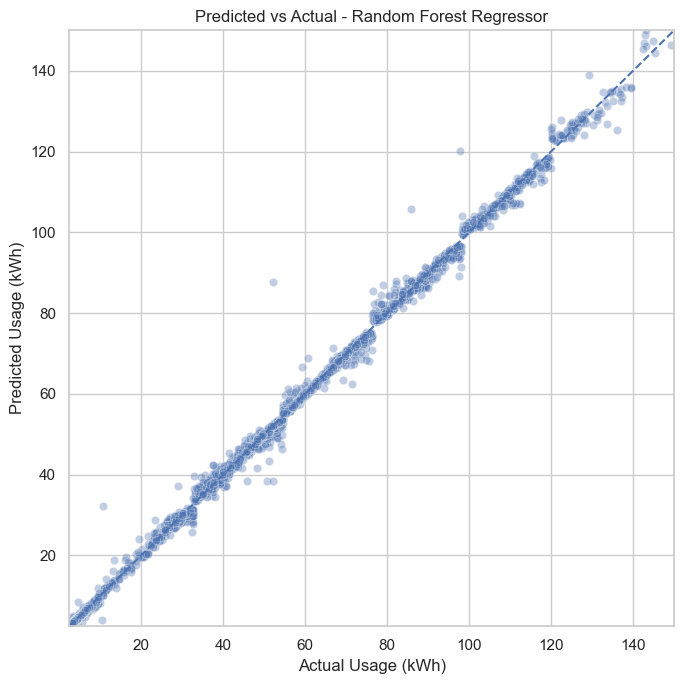

In [19]:

# Predicted vs actual
plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_test, y=best_pred, alpha=0.35)
lims = [
    min(y_test.min(), best_pred.min()),
    max(y_test.max(), best_pred.max())
]
plt.plot(lims, lims, linestyle="--")
plt.xlim(lims)
plt.ylim(lims)
plt.title(f"Predicted vs Actual - {best_name}")
plt.xlabel("Actual Usage (kWh)")
plt.ylabel("Predicted Usage (kWh)")
plt.tight_layout()
plt.show()


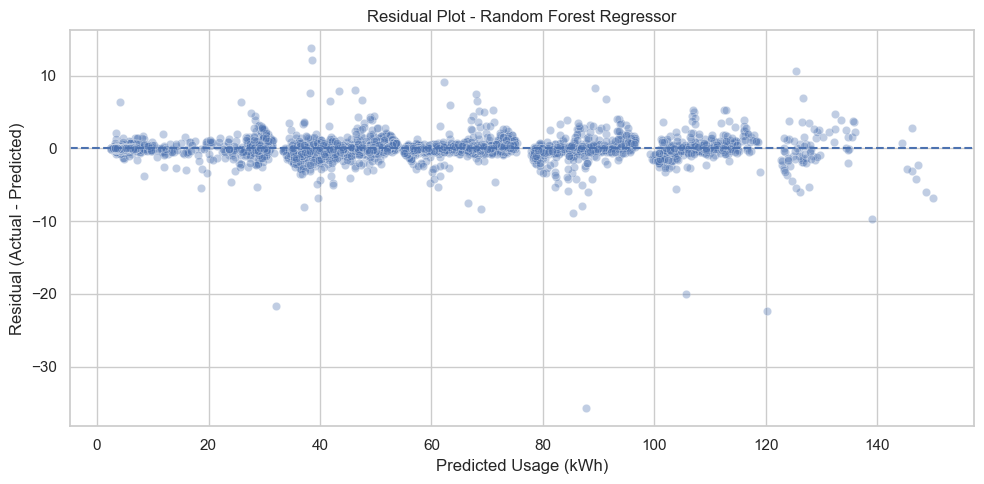

In [20]:

# Residual plot
plt.figure(figsize=(10, 5))
sns.scatterplot(x=best_pred, y=residuals, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.title(f"Residual Plot - {best_name}")
plt.xlabel("Predicted Usage (kWh)")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()



**Diagnostic observation:** Comment on clustering around the diagonal, spread of residuals, and any visible systematic pattern. This commentary must be based on the actual plot.


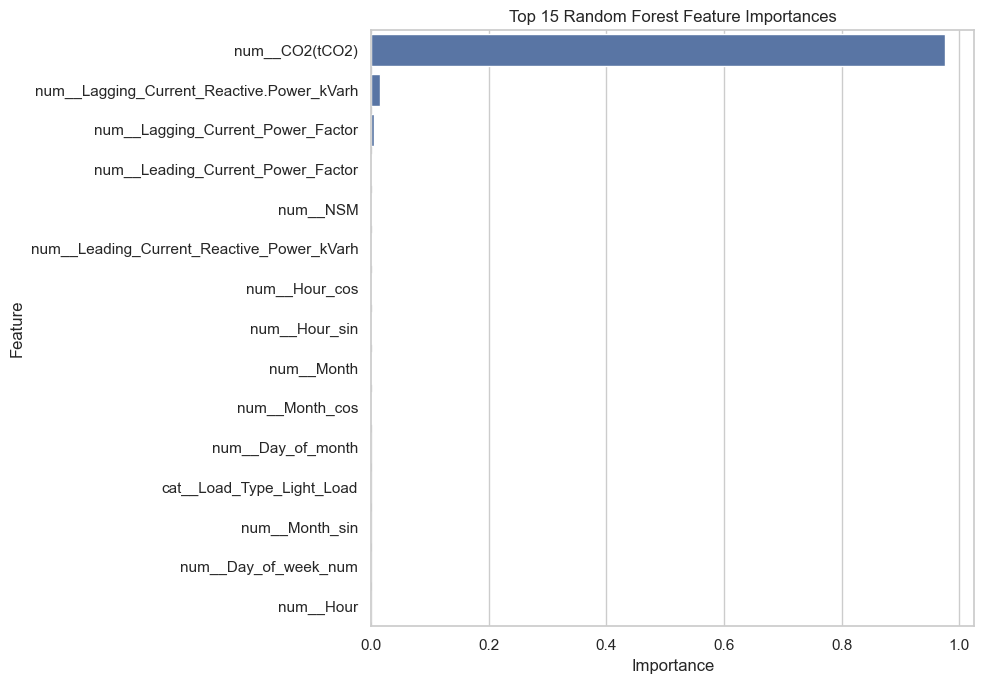

,Feature,Importance
2,num__CO2(tCO2),0.9765
0,num__Lagging_Current_Reactive.Power_kVarh,0.0147
3,num__Lagging_Current_Power_Factor,0.0047
4,num__Leading_Current_Power_Factor,0.0012
5,num__NSM,0.0007
1,num__Leading_Current_Reactive_Power_kVarh,0.0003
13,num__Hour_cos,0.0003
12,num__Hour_sin,0.0003
8,num__Month,0.0002
15,num__Month_cos,0.0002


In [21]:

# Feature importance for the best available tree-based model
tree_name = "Random Forest Regressor"
tree_model = fitted_models[tree_name]

feature_names = tree_model.named_steps["preprocess"].get_feature_names_out()
importances = tree_model.named_steps["model"].feature_importances_

importance_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df)



**Observation:** Identify the most influential features in the tree-based model. Relate them to the dataset and the reference paper, while avoiding unsupported causal claims.


## 10. Coefficient interpretation for the linear baseline

In [22]:

linear_model = fitted_models["Linear Regression"]

linear_feature_names = linear_model.named_steps["preprocess"].get_feature_names_out()
linear_coefficients = linear_model.named_steps["model"].coef_

coef_df = (
    pd.DataFrame({"Feature": linear_feature_names, "Coefficient": linear_coefficients})
    .assign(AbsCoefficient=lambda d: d["Coefficient"].abs())
    .sort_values("AbsCoefficient", ascending=False)
)

display(coef_df.head(15))


,Feature,Coefficient,AbsCoefficient
2,num__CO2(tCO2),26.4013,26.4013
0,num__Lagging_Current_Reactive.Power_kVarh,5.2675,5.2675
3,num__Lagging_Current_Power_Factor,1.7606,1.7606
4,num__Leading_Current_Power_Factor,1.3634,1.3634
25,cat__Load_Type_Light_Load,-1.0717,1.0717
27,cat__Load_Type_Medium_Load,0.8888,0.8888
12,num__Hour_sin,-0.7702,0.7702
8,num__Month,-0.6193,0.6193
23,cat__Day_of_week_Tuesday,0.4911,0.4911
15,num__Month_cos,0.3733,0.3733



**Interpretation note:** A positive coefficient means the model predicts higher usage as that encoded/scaled feature increases, holding the other model inputs fixed. Because numerical features are standardized and categorical variables are one-hot encoded, interpret coefficient magnitude carefully.



# 11. Review 1 checklist

Before submission, verify every item below.

### Dataset & EDA
- [ ] Shape, dtypes, missing values, duplicates reported
- [ ] Target distribution shown
- [ ] Distribution plots for numerical features
- [ ] Correlation heatmap
- [ ] At least two feature-target scatter plots
- [ ] A Markdown observation follows each major visualisation

### Preprocessing & Feature Engineering
- [ ] Missing-value strategy is justified
- [ ] Duplicate/outlier check is shown
- [ ] Categorical variables encoded inside a pipeline
- [ ] Scaling fitted only on training data
- [ ] 80:20 held-out split used consistently
- [ ] At least one engineered feature explained

### Regression
- [ ] All 10 required algorithms trained
- [ ] Same held-out test set used
- [ ] Comparison table contains R², RMSE, MAE
- [ ] Results ranked by R²
- [ ] GridSearchCV/RandomizedSearchCV used for at least 2 models
- [ ] Best parameters and improvement documented
- [ ] 5-fold CV R² reported for two best models
- [ ] Predicted-vs-actual plot
- [ ] Residual plot
- [ ] Tree-based feature importance plot

### Notebook hygiene
- [ ] Run top-to-bottom with no errors
- [ ] All outputs visible
- [ ] Random state = 42
- [ ] Markdown explains each major block
- [ ] README cites AI assistance, if used



# 12. Classification Part A - important project decision

The supplied capstone guideline requires five Part-A classifiers in Review 1: Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, and SVM. The guideline does **not** specify the classification target in the file set supplied here.

The dataset contains a natural categorical field, `Load_Type`, but the reference paper uses `Load_Type` as an input variable for regression rather than as a prediction target.

**Do not silently assume the classification target for the final submission. Confirm the team's assigned classification target before implementing this section.**
